# GEFI demo with exported COCO examples
Run from the repository root with PyTorch, torchvision, OpenAI CLIP, NumPy, Pillow, matplotlib, and tqdm installed. Select an image ID below. No FiftyOne database or original COCO dataset is needed.

Each segmentation filename supplies a caption anchor. For each object, the demo shows its segmentation, the image interaction anchored on its caption phrase, and caption-token interactions anchored on its image region. Multi-token text anchors use the mean of their individual interaction maps.


In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import torch
from matplotlib import pyplot as plt
from torch.nn import functional as F

from gefi import gefi
import model_adapter
from interaction_visualization import load_example
from interaction_visualization.visualize_all import visualize_interactions
from utils import log 

import random, os

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
plt.rcParams["font.family"] = "monospace"


In [2]:
# Load model
device = "cuda" if torch.cuda.is_available() else "cpu"
clipmodel, preprocess = model_adapter.load_clip("ViT-B/32", device=device)
clipmodel.eval()
tokenizer = model_adapter.OpenAIClipTokenizerAdapter()
clip_inres = int(clipmodel.visual.input_resolution)
log(f"Device: {device}, Image resolution: {clip_inres}")


INFO[10/27/26,15:21:25]:	Device: cuda, Image resolution: 224


In [3]:
# Initialize the explainer
num_samples = 5000
expl_gefi = gefi.GEFI4Clip(
    num_samples, (clip_inres, clip_inres), 77,
    img_baseline="blur", txt_baseline=0,
    patch_size=32, truncation=0.25, img_ratio=0.8,
)

INFO[10/27/26,15:21:25]:	GEFI initializing query masks, might take some time


In [ ]:
# Read sample input under the ./examples folder
available_examples = os.listdir("./examples")
available_examples = [fname for fname in available_examples if 'gif_example' not in fname]
log(f"Available example ids: {available_examples}")
example_id = available_examples[2]      # <======= Change this value to switch to other examples
log(f"==> Reading from {example_id}")
example = load_example.read_existing_example(example_id)
log(example["caption"])
log(f"Anchors: {[anchor["keyword"] for anchor in example["anchors"]]}")

img, txt, anchors = load_example.prepare_example(example, preprocess, tokenizer, clip_inres, device)
with torch.no_grad():
    image_embedding = F.normalize(clipmodel.encode_image(img), dim=-1)
    text_embedding = F.normalize(clipmodel.encode_text(txt), dim=-1)
    similarity = (image_embedding @ text_embedding.T).item()
log(f"CLIP cosine similarity: {similarity:.4f}")

INFO[10/27/26,15:21:27]:	Available example ids: ['000000084362', '000000102707', '000000163951', '000000174231', '000000189806', '000000456662', '000000491464', '000000577584']
INFO[10/27/26,15:21:27]:	==> Reading from 000000163951
INFO[10/27/26,15:21:27]:	An assortment of items including a miniature boom box, chair, banana and flashlight.
INFO[10/27/26,15:21:27]:	Anchors: ['chair', 'banana']
INFO[10/27/26,15:21:28]:	CLIP cosine similarity: 0.3438


## Cross-modal Interactions
This repository implements a GEFI-PM version to investigate pairwise feature interaction across and textual and visual modality.
This is achieved by first collecting observations following the query masks generated at the initialization stage of GEFI; the interactions on specific anchor(s) can be derived by reusing the collected observations.


In [5]:
def compute_interactions(explainer, observations, img, anchors):
    all_indices = torch.cat([anchor["token_indices"] for anchor in anchors])
    unique_indices, inverse = torch.unique(all_indices, return_inverse=True)
    token_maps = explainer.interaction_anchored_on_text(observations, unique_indices)

    anchor_masks = torch.stack([anchor["mask"] for anchor in anchors])
    image_maps = explainer.interaction_anchored_on_image(observations, anchor_masks)

    results = []
    offset = 0
    for i, anchor in enumerate(anchors):
        count = len(anchor["token_indices"])
        map_indices = inverse[offset:offset + count]
        # One phrase may consist of several model tokens. Aggregate all of them.
        text_to_image = token_maps[map_indices].mean(dim=0)
        offset += count

        enhanced = explainer.visual_enhancement(img, text_to_image).detach().cpu()
        image_to_text = image_maps[i]
        results.append({**anchor, "text_to_image": text_to_image,
                        "enhanced_text_to_image": enhanced,
                        "image_to_text": image_to_text.detach().cpu()})
    return results

# Collecting observations & computing interactions
obs = expl_gefi.collect_observations(clipmodel, img, txt, cv_mode=2)

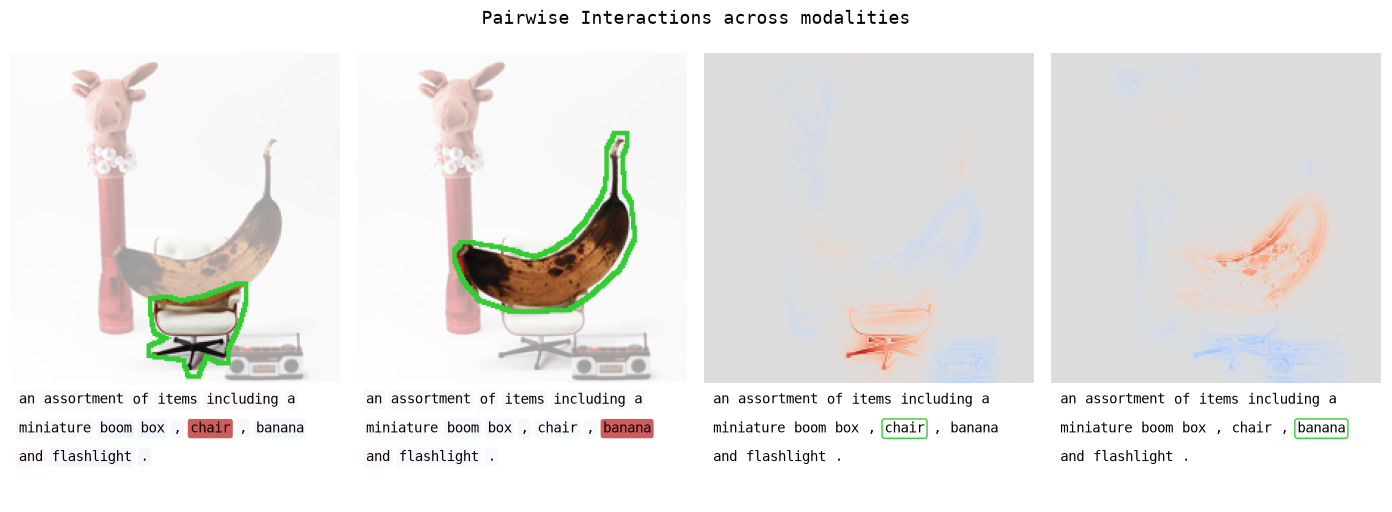

In [6]:
# Change the anchors to derive interactions anchoring on alternative features without repeatedly querying the model
interactions = compute_interactions(expl_gefi, obs, img, anchors)

T = 0.3 # This is an example-specific choice for visualization of token interaction scores, 
        # increasing the temperature to show less active features, 
        # decreasing the value to highlight the most interaction features
fig, axes = visualize_interactions(
    example, interactions, img, txt, tokenizer, 
    temperature=T, text_band_height=80,
    title='Pairwise Interactions across modalities'
)
# fig.suptitle()
plt.show()


## Image and text attribution
First-order Attributions are supported by GEFI framework, which can be easily obtained by reusing the collected observations.
Following image heatmap shows attribution; caption boxes show signed token attribution (red positive, blue negative).

It is noteworthy that, for some examples, first-order attributions may show different patterns than the pairwise interactions, which indicates that strong interactions do not necessarily dominate model decisions.


In [7]:
# Attribution from the same observations used for interactions.
image_attr, enhanced_image_attr = expl_gefi.attribution_img(img, obs, visual_enhanced=True)
# The attribution helper returns CPU scores; keep its text mask on CPU too.
text_attr = expl_gefi.attribution_txt(txt.cpu(), obs)


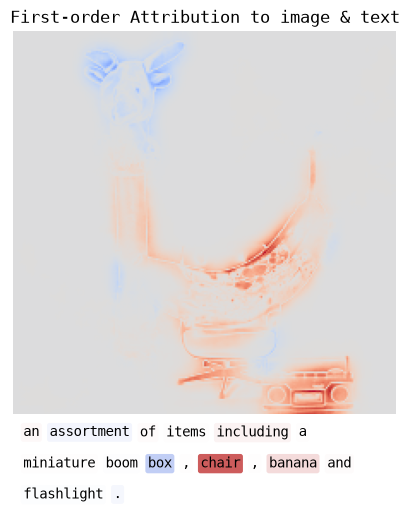

In [8]:
from matplotlib.colors import TwoSlopeNorm
from interaction_visualization import score_scaling, visualize_text

ATTR_TEMPERATURE = 0.2
positions = tokenizer.content_positions(txt[0]).cpu()
content_ids = txt[0, positions.to(txt.device)].detach().cpu()
tokens, has_spaces = visualize_text.decode_clip_tokens(tokenizer, content_ids)
text_scores = text_attr.detach().cpu()[positions]

heatmap = enhanced_image_attr.detach().cpu().numpy()
limit = max(float(np.abs(heatmap).max()), 1e-8)

width, height = example["image"].size
text_band_height = 80
panel_width = 4

attr_fig, attr_ax = plt.subplots(figsize=(panel_width, panel_width * (height + text_band_height) / width + 0.4,))
# attr_fig.suptitle("First-order Attribution to image & text", fontsize=11, y=0.98)
attr_fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=0.90)
attr_ax.set_title("First-order Attribution to image & text")
attr_ax.imshow(
    heatmap, cmap="coolwarm",
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
)
width, height = example["image"].size
_, attr_boxes = visualize_text.draw_text_only(
    attr_ax, tokens, has_spaces, img_width=width, img_height=height,
    band_height=60, fontsize=10, gap_word=6, gap_subword=2,
    return_bbox_infos=True,
)
alphas = score_scaling.scores_to_alpha(
    text_scores, temperature=ATTR_TEMPERATURE
)
pos_color = (205/255, 92/255, 92/255)
neg_color = (65/255, 105/255, 225/255)
for (info, _), score, alpha in zip(attr_boxes, text_scores.tolist(), alphas):
    color = pos_color if score >= 0 else neg_color
    visualize_text.set_token_bbox_color(
        info, facecolor=(*color, alpha), edgecolor="none"
    )
attr_fig.token_bbox_infos = attr_boxes
plt.show()
